# Ember

**Can a small quantum computer help forecast where a wildfire goes next?**

### Problem

- 2023 was Canada's worst fire season on record: 17.2 million ha burned (CIFFC, Canada Report 2023).
- Yellowknife: ~20,000 people ordered to leave as fire ZF015 approached (August 2023).
- Evacuation planning needs to know **where the fire edge will be in 1–3 days**, and in
  **which direction** it is moving.

### Proposed solution

**Ember:** for a fire burning 3+ days, predict how far the edge moves in each of 8
directions, +24 h and +72 h ahead, from free satellite hotspot data.

```
satellite hotspots → 8 sector radii per day → 5 inputs × 5 days
                   → 5-qubit circuit (fixed) → 20 features → ridge (trained) → forecast
```

| Choice | Why |
|---|---|
| 8 sectors | direction matters for evacuation; 8 numbers a day keep the data simple |
| Quantum reservoir | fixed circuit, only ridge is trained → cheap; short circuit → runs on today's noisy hardware |
| Honest test | settings frozen on 2022, scored once on unseen 2023 fires, against simple, classical and physics baselines |
| Real hardware | one fire run on `ibm_fez` to check the forecasts survive noise |

**Short answer**
- Quantum is close to classical reservoirs (worse than `esn20` at +24 h, no clear gap at +72 h); no quantum advantage claimed.
- FBP (Canada's physics model) has the smallest error.
- Real `ibm_fez` hardware: average error close to a perfect simulator; single forecasts noisier.

**Run:** `pip install numpy==2.5.4 pandas==3.1.1 qiskit==2.6.1 ipython`, then run all.
No other files, data download or IBM account needed.

| Live in this notebook | Saved (too slow to rerun here) |
|---|---|
| Reservoir code, circuit simulation, simulator check, hardware forecasts recomputed from saved measurements | Training on all fires, result tables, figures, `ibm_fez` measurements |

**Experiments**

| ID | Tests | ID | Tests |
|---|---|---|---|
| E1 | 2023 test scores | E7 | reservoir + raw inputs |
| E3 | settings search (2022) | E8 | Yellowknife distance |
| E6 | real `ibm_fez` run | E10 | rebuilt shape vs CWFIS outline |

Robustness checks (E2 wind, E4 seeds, E5 shots, E9 missing days) are saved in `results/`, not shown here.

**Words**

| Word | Meaning |
|---|---|
| Sector | 1 of 8 directions, clockwise from north: 0 N, 1 NE, 2 E, 3 SE, 4 S, 5 SW, 6 W, 7 NW |
| Radius $r_k(t)$ | km from fire centre to furthest burned point in sector $k$, end of day $t$ |
| Lead $h$ | 1 day (+24 h) or 3 days (+72 h) |
| MAE | average miss in km (lower better) |
| Skill | $1-\mathrm{MAE}/\mathrm{MAE}_\text{persistence}$ (above 0 beats persistence) |
| IoU | shape overlap ÷ union (1 = perfect) |

In [1]:
# Embedded data: a compressed copy of the saved result files (results/, hardware/,
# figures/), so this notebook needs no other files. The next cell checks every
# file against its SHA-256 checksum.
BUNDLE = "..."

### Setup

Unpacks the hidden `BUNDLE` above into `FILES` (name → bytes, in memory only) and checks
each file's SHA-256. Helpers read one file each.

In [2]:
import base64
import gzip
import hashlib
import io
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display

# Unpack the bundle: {file name: bytes}, each checked against its SHA-256.
FILES = {}
for name, item in json.loads(gzip.decompress(base64.b64decode(BUNDLE))).items():
    data = base64.b64decode(item["b64"])
    assert hashlib.sha256(data).hexdigest() == item["sha256"], f"corrupted: {name}"
    FILES[name] = data

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

# Readers that take a file name and return its contents from FILES.
def read_json(name):
    return json.loads(FILES[name])

def read_csv(name, **options):
    return pd.read_csv(io.BytesIO(FILES[name]), **options)

def load_array(name):
    return np.load(io.BytesIO(FILES[name]), allow_pickle=False)

def show_figure(name):
    display(Image(data=FILES["figures/" + name], format="png", width=950))

def mae(y, yhat):
    """Mean absolute error over the supplied targets."""
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(yhat))))

print(f"{len(FILES)} embedded files verified; distances and errors are in km.")

25 embedded files verified; distances and errors are in km.


## Data and sector geometry

**Fire → 8 numbers a day**
1. Fire centre: middle of the largest day-1 hotspot group (linked within 2 km).
2. Cut into 8 sectors like a pizza.
3. Radius $r_k(t)$ = furthest burned point so far; never shrinks.
4. New hotspots count only within 2 km of the fire; max 30 km growth a day.

**Target:** advance from the end of day $t$:
$$y_k^{(h)}(t)=r_k(t+h)-r_k(t),\qquad h\in\{1,3\}.$$
First forecast on fire day 3. The model sees days $t-4$ to $t$.

**Inputs** (per sector, per day; weather = daily median over the fire's hotspots)

| Qubit | Input | Meaning |
|---|---|---|
| 0 | `w_k` | wind toward the sector (km/h) |
| 1 | `isi` | Initial Spread Index: how fast fire could spread |
| 2 | `dd_km` | today's advance, $r_k(t)-r_k(t-1)$ (km) |
| 3 | `bui` | Buildup Index: dry fuel deeper down |
| 4 | `rh` | relative humidity (%) |

**Years:** train 2018–2021 · choose settings 2022 · test 2023 once.

In [3]:
counts = pd.DataFrame.from_dict(read_json("results/fire_counts.json"), orient="index")
counts.index.name = "year"
display(counts[["split", "fires", "sector_rows", "origin_days"]])
# Fires per split: train 2018-2021, val 2022, test 2023.
display(counts.groupby("split", sort=False)[["fires"]].sum())

,split,fires,sector_rows,origin_days
year,,,,
2018,train,134,43824,5076
2019,train,44,17200,2018
2020,train,7,1816,206
2021,train,193,63464,7354
2022,val,102,40552,4763
2023,test,392,171392,20248


,fires
split,
train,378
val,102
test,392


### E10: does the rebuilt shape match the real fire?

IoU of each 2023 fire's final shape vs the CWFIS season-end outline (buffered hotspots; median over fires).

| Shape | Meaning |
|---|---|
| eight-point outline | polygon through the 8 radii (what the model sees) |
| buffered hotspots | every hotspot as a 375 m disc (raw data coverage) |

0.65 vs 0.83 → 8 sectors are coarse but follow the fire.

In [4]:
rebuild = read_json("results/e10_2023.json")
print(f"E10 median IoU, eight-point outline: {rebuild['median_iou']:.6f}")
print(f"E10 median IoU, buffered hotspots: {rebuild['median_iou_buffered']:.6f}")

E10 median IoU, eight-point outline: 0.650093
E10 median IoU, buffered hotspots: 0.827641


## Quantum reservoir

**Idea:** a fixed random circuit turns the input history into features; only the
read-out on top is trained.

**One window** = one sector, 5 inputs × 5 days, scaled to $[0,1]$ (min/max from train).
Start in $|00000\rangle$, then each day, oldest first:

| Step | Gate | Role |
|---|---|---|
| Encode | $R_Y(\gamma\,g_i\,u_i)$ on qubit $i$ | today's input turns its qubit |
| Link | CZ on 0–1, 1–2, 2–3, 3–4 | mix neighbours |
| Scramble | $R_Z(b_i)\,R_Y(a_i)$ | fixed random turns |

State carries day to day (memory). Read **20 features**: 5 $\langle Z_i\rangle$ +
10 $\langle Z_iZ_j\rangle$ + 5 $\langle X_i\rangle$ → ridge → forecast (clipped ≥ 0).

| Part | Status |
|---|---|
| gains $g_i\in[0.5,1.5]$, angles $a_i,b_i$ | fixed, seed 7 |
| window length, $\gamma$, input order, $\lambda$ | chosen on 2022 (E3) |
| ridge weights | trained on 2018–2021 |

Next cell: full reservoir code (= `ember/reservoir.py`). Feature modes: `exact`
(Qiskit), `numpy` (fast copy, used for training), `sampled` (finite shots; 15 Z/ZZ features, needs `qiskit_aer`).

In [5]:
from itertools import combinations

import numpy as np


def feature_names(n):
    """Names in read-out order: Z, lexicographic ZZ, then X."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer")
    return ([f"Z{i}" for i in range(n)]
            + [f"Z{i}Z{j}" for i, j in combinations(range(n), 2)]
            + [f"X{i}" for i in range(n)])


def counts_to_features(counts: dict[str, int], n):
    """Convert Qiskit Z-basis counts to Z and ZZ expectations."""
    size = len(feature_names(n)) - n
    pairs = list(combinations(range(n), 2))
    features = np.zeros(size)
    total = 0
    for key, count in counts.items():
        bits = key.replace(" ", "")[::-1]  # The only count-key reversal.
        if len(bits) != n or any(bit not in "01" for bit in bits):
            raise ValueError(f"expected a {n}-bit count key, got {key!r}")
        if count < 0:
            raise ValueError("counts must be nonnegative")
        signs = np.array([1.0 - 2.0 * int(bit) for bit in bits])
        features[:n] += count * signs
        features[n:] += count * np.array([signs[i] * signs[j] for i, j in pairs])
        total += count
    if total <= 0:
        raise ValueError("counts must contain at least one shot")
    return features / total


def _ry(theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]])


class ChainReservoir:
    """Restart at zero per window; carry the state through all its days."""

    def __init__(self, n=5, gamma=np.pi / 2, seed=7,
                 entangler="cz_chain", ent_seed=None):
        feature_names(n)  # Validate the register size.
        if not np.isfinite(gamma):
            raise ValueError("gamma must be finite")
        if entangler not in ("cz_chain", "haar"):
            raise ValueError("entangler must be 'cz_chain' or 'haar'")
        self.n, self.gamma = n, float(gamma)
        self.entangler = entangler
        rng = np.random.default_rng(seed)
        self.gains = rng.uniform(0.5, 1.5, size=n)
        self.w_angles = rng.uniform(0, 2 * np.pi, size=(n, 2))
        self.gains.flags.writeable = False
        self.w_angles.flags.writeable = False

        ent_rng = np.random.default_rng(ent_seed)
        gates = []
        for _ in range(n - 1):
            if entangler == "cz_chain":
                gate = np.diag([1, 1, 1, -1]).astype(complex)
            else:
                z = (ent_rng.normal(size=(4, 4))
                     + 1j * ent_rng.normal(size=(4, 4)))
                q, r = np.linalg.qr(z)
                diagonal = np.diag(r)
                gate = q * (diagonal / np.abs(diagonal))
            gate.flags.writeable = False
            gates.append(gate)
        self._entanglers = tuple(gates)

        # Compile the fixed layer entirely in NumPy, qubit 0 leftmost.
        dim = 2 ** n
        layer = np.eye(dim, dtype=complex)
        for i, gate in enumerate(self._entanglers):
            operator = np.kron(np.kron(np.eye(2 ** i), gate),
                               np.eye(2 ** (n - i - 2)))
            layer = operator @ layer
        for i, (a, b) in enumerate(self.w_angles):
            gate = np.diag(np.exp([-0.5j * b, 0.5j * b])) @ _ry(a)
            operator = np.kron(np.kron(np.eye(2 ** i), gate),
                               np.eye(2 ** (n - i - 1)))
            layer = operator @ layer
        self._layer = layer
        indices = np.arange(dim)
        signs = 1.0 - 2.0 * ((indices[:, None] >> np.arange(n - 1, -1, -1)) & 1)
        self._z_signs = np.column_stack(
            [signs] + [signs[:, i] * signs[:, j]
                       for i, j in combinations(range(n), 2)])

    def _validate(self, values, ndim):
        values = np.asarray(values, dtype=float)
        if values.ndim != ndim or values.shape[-1] != self.n:
            shape = "(L, n)" if ndim == 2 else "(N, L, n)"
            raise ValueError(f"expected input shape {shape} with n={self.n}")
        if (not np.isfinite(values).all() or np.any(values < -1e-12)
                or np.any(values > 1 + 1e-12)):
            raise ValueError("inputs must be finite and scaled to [0, 1]")
        return values

    def circuit(self, window):
        """Build an unmeasured circuit, oldest day first."""
        from qiskit import QuantumCircuit

        window = self._validate(window, 2)
        qc = QuantumCircuit(self.n)
        for day in window:
            for i in range(self.n):
                qc.ry(self.gamma * self.gains[i] * day[i], i)
            for i, gate in enumerate(self._entanglers):
                if self.entangler == "cz_chain":
                    qc.cz(i, i + 1)
                else:
                    # Qiskit's first qarg is the low bit of this local gate.
                    qc.unitary(gate, [i + 1, i])
            for i, (a, b) in enumerate(self.w_angles):
                qc.ry(a, i)
                qc.rz(b, i)
        return qc

    def measured_circuit(self, window, basis="Z"):
        """Measure every qubit in the Z or X basis."""
        if basis not in ("Z", "X"):
            raise ValueError("basis must be 'Z' or 'X'")
        qc = self.circuit(window)
        if basis == "X":
            qc.h(range(self.n))
        qc.measure_all()
        return qc

    def features_exact(self, window):
        """Evaluate Pauli expectations using Qiskit's Statevector."""
        from qiskit.quantum_info import Pauli, Statevector

        state = Statevector.from_instruction(self.circuit(window))
        terms = ([('Z', (i,)) for i in range(self.n)]
                 + [('Z', pair) for pair in combinations(range(self.n), 2)]
                 + [('X', (i,)) for i in range(self.n)])
        features = []
        for axis, qubits in terms:
            label = ["I"] * self.n
            for i in qubits:
                label[self.n - 1 - i] = axis
            features.append(state.expectation_value(Pauli("".join(label))).real)
        return np.array(features)

    def _numpy_batch(self, windows):
        """Propagate a batch of big-endian statevectors without Qiskit."""
        count = len(windows)
        state = np.zeros((count, 2 ** self.n), dtype=complex)
        state[:, 0] = 1.0
        for day in range(windows.shape[1]):
            for i in range(self.n):
                theta = self.gamma * self.gains[i] * windows[:, day, i]
                c = np.cos(theta / 2)[:, None, None]
                s = np.sin(theta / 2)[:, None, None]
                tensor = state.reshape(count, 2 ** i, 2, 2 ** (self.n - i - 1))
                zero, one = tensor[:, :, 0, :].copy(), tensor[:, :, 1, :].copy()
                tensor[:, :, 0, :] = c * zero - s * one
                tensor[:, :, 1, :] = s * zero + c * one
            state = state @ self._layer.T
        features = np.empty((count, len(feature_names(self.n))))
        z_count = self._z_signs.shape[1]
        features[:, :z_count] = (state.real ** 2 + state.imag ** 2) @ self._z_signs
        for i in range(self.n):
            tensor = state.reshape(count, 2 ** i, 2, 2 ** (self.n - i - 1))
            features[:, z_count + i] = 2 * np.sum(
                (tensor[:, :, 0, :].conj() * tensor[:, :, 1, :]).real, axis=(1, 2))
        return features

    def features_numpy(self, window):
        """Compute all observables with the pure-NumPy validation twin."""
        window = self._validate(window, 2)
        return self._numpy_batch(window[None, ...])[0]

    def _sampled_matrix(self, windows, shots, seed, noise_model=None):
        from qiskit import transpile
        from qiskit_aer import AerSimulator

        if not isinstance(shots, (int, np.integer)) or shots <= 0:
            raise ValueError("shots must be a positive integer")
        size = len(feature_names(self.n)) - self.n
        if not len(windows):
            return np.empty((0, size))
        simulator = AerSimulator(noise_model=noise_model, max_parallel_threads=1)
        circuits = [self.measured_circuit(w) for w in windows]
        circuits = transpile(circuits, simulator, seed_transpiler=seed)
        result = simulator.run(circuits, shots=int(shots), seed_simulator=seed).result()
        return np.array([counts_to_features(result.get_counts(i), self.n)
                         for i in range(len(windows))])

    def features_sampled(self, window, shots, seed, noise_model=None):
        """Estimate Z and ZZ features from local Aer counts."""
        window = self._validate(window, 2)
        return self._sampled_matrix(window[None, ...], shots, seed, noise_model)[0]

    def feature_matrix(self, windows, mode="exact", shots=None, seed=None):
        """Return one feature row per window; NumPy batches use bounded memory."""
        if mode not in ("exact", "numpy", "sampled"):
            raise ValueError("mode must be 'exact', 'numpy', or 'sampled'")
        windows = self._validate(windows, 3)
        if mode == "sampled":
            return self._sampled_matrix(windows, shots, seed)
        features = np.empty((len(windows), len(feature_names(self.n))))
        if mode == "exact":
            for i, window in enumerate(windows):
                features[i] = self.features_exact(window)
        else:
            for start in range(0, len(windows), 4096):
                stop = start + 4096
                features[start:stop] = self._numpy_batch(windows[start:stop])
        return features

### E3: settings search (2022 only)

| Setting | Tried |
|---|---|
| `L` (days) | 3, 5, 7 |
| `gamma` | $\pi/4$, $\pi/2$, $3\pi/4$ |
| input order | `w_k, isi, dd_km, …` or `w_k, dd_km, isi, …` |
| $\lambda$ | best of $10^{-6}$ … $10^{2}$ |

18 settings, ranked by skill (mean of both leads). Winner: L 5, $\gamma=\pi/4$.
All skills slightly below 0, top settings very close.

In [6]:
e3 = read_csv("results/e3_val.csv")
e3["input_order"] = e3.input_map.map(lambda text: ", ".join(json.loads(text)))
e3["gamma"] = (e3.gamma / np.pi).map(lambda value: f"{value:.2f}*pi")
ranked = e3.sort_values("val_skill_mean", ascending=False).reset_index(drop=True)
print(f"E3 tried {len(e3)} settings on 2022 validation; top five by mean skill:")
display(ranked[["L", "gamma", "input_order", "lam_1", "val_mae_1",
                "lam_3", "val_mae_3", "val_skill_mean"]].head(5))

E3 tried 18 settings on 2022 validation; top five by mean skill:


,L,gamma,input_order,lam_1,val_mae_1,lam_3,val_mae_3,val_skill_mean
0,5,0.25*pi,"w_k, isi, dd_km, bui, rh",0.000001,0.302704,0.000001,0.766907,-0.070435
1,5,0.25*pi,"w_k, dd_km, isi, bui, rh",0.000001,0.304426,0.000001,0.765697,-0.072906
2,5,0.75*pi,"w_k, dd_km, isi, bui, rh",0.000001,0.304979,0.000001,0.767048,-0.074829
3,5,0.75*pi,"w_k, isi, dd_km, bui, rh",10.000000,0.305297,10.000000,0.769821,-0.077232
4,5,0.50*pi,"w_k, isi, dd_km, bui, rh",0.000001,0.308671,0.000001,0.769900,-0.083664


### Frozen settings and one circuit

Loads the E3 winner and 88 saved Yellowknife (ZF015) windows (11 days × 8 sectors),
then draws the circuit for the first window.

In [7]:
# E3 winner, frozen before any test fire was scored.
frozen = read_json("results/frozen_config.json")
choices = {key: frozen[key] for key in ("L", "gamma", "input_map", "lambdas", "reservoir_seed")}
print(json.dumps(choices, indent=2))
reservoir = ChainReservoir(gamma=frozen["gamma"], seed=frozen["reservoir_seed"])
# 88 Yellowknife windows: (window, day, input), already scaled to [0, 1].
with load_array("hardware/zf015_case.npz") as case:
    W = case["windows"].copy()
    case_rows = pd.DataFrame({
        "date": pd.to_datetime(case["dates"]),
        "sector": case["sectors"],
    })
assert W.shape == (88, 5, 5)
print("ZF015 window archive shape:", W.shape)
print(reservoir.circuit(W[0]).draw("text", fold=110))
names = feature_names(reservoir.n)
assert len(names) == 20
print("Feature names (20):", ", ".join(names))

{
  "L": 5,
  "gamma": 0.7853981633974483,
  "input_map": [
    "w_k",
    "isi",
    "dd_km",
    "bui",
    "rh"
  ],
  "lambdas": {
    "1": 1e-06,
    "3": 1e-06
  },
  "reservoir_seed": 7
}
ZF015 window archive shape: (88, 5, 5)


      ┌─────────────┐    ┌────────────┐┌──────────────┐┌─────────────┐                               »
q_0: ─┤ Ry(0.45246) ├──■─┤ Ry(5.4887) ├┤ Rz(0.033083) ├┤ Ry(0.49162) ├───────────────────────■───────»
     ┌┴─────────────┴┐ │ └────────────┘└┬────────────┬┘└┬────────────┤┌───────────────┐      │       »
q_1: ┤ Ry(0.0043449) ├─■───────■────────┤ Ry(5.1599) ├──┤ Rz(5.0081) ├┤ Ry(0.0055294) ├──────■───────»
     └───┬───────┬───┘         │        └────────────┘  ├────────────┤└─┬───────────┬─┘  ┌───────┐   »
q_2: ────┤ Ry(0) ├─────────────■──────────────■─────────┤ Ry(2.9401) ├──┤ Rz(1.904) ├────┤ Ry(0) ├───»
       ┌─┴───────┴──┐                         │         └────────────┘  ├───────────┴┐ ┌─┴───────┴──┐»
q_3: ──┤ Ry(0.4308) ├─────────────────────────■───────────────■─────────┤ Ry(1.7494) ├─┤ Rz(1.6014) ├»
       ├────────────┤                                         │         ├────────────┤ ├────────────┤»
q_4: ──┤ Ry(0.2189) ├─────────────────────────────────────────■─────────┤

### Check: fast NumPy simulator = Qiskit exact

Must agree within $10^{-10}$ (training used NumPy).

In [8]:
numpy_features = reservoir.feature_matrix(W[:2], mode="numpy")
exact_features = reservoir.feature_matrix(W[:2], mode="exact")
max_diff = float(np.max(np.abs(numpy_features - exact_features)))
print(f"NumPy / exact feature max difference: {max_diff:.12e}")
assert max_diff <= 1e-10

NumPy / exact feature max difference: 7.771561172376e-16


## Baselines

| `model` | What | Why |
|---|---|---|
| `qrc` | **our quantum reservoir** | |
| `persistence` | $h$ × today's advance | simplest; must beat it |
| `mean` | average training advance | floor |
| `fbp` | physics spread rate × burn time × wind share × $h$ | knows fuel type; we don't |
| `raw` | ridge on raw inputs, no circuit | does the circuit help? |
| `esn5`, `esn20` | classical random network (5 / 20 units) + ridge | same idea, no qubits |
| `qrc_raw` (E7) | reservoir features + raw inputs | do they combine? |

## Test 2023 results

E1: all models frozen, scored once on 392 test fires.

- `mae [lo, hi]`: km, 95% interval (resampling whole fires)
- `mae_growing`: MAE on sectors that really moved
- Paired table: `qrc` minus other model; **negative favours `qrc`**; clear if interval misses 0

,model,lead_h,"mae [mae_lo, mae_hi]",skill,iou,mae_growing
0,esn20,24,"0.350293 [0.322225, 0.376369]",-0.003746,0.762824,1.429400
1,esn5,24,"0.357794 [0.330522, 0.383042]",-0.025237,0.757984,1.473719
2,fbp,24,"0.261797 [0.232591, 0.288843]",0.249836,0.781474,1.593038
3,mean,24,"0.387043 [0.359699, 0.412127]",-0.109049,0.749887,1.495680
4,persistence,24,"0.348986 [0.306802, 0.388743]",0.000000,0.917901,1.705278
5,qrc,24,"0.359898 [0.330036, 0.387195]",-0.031268,0.757289,1.455600
6,qrc_raw,24,"0.347457 [0.317997, 0.374092]",0.004380,0.765207,1.420634
7,raw,24,"0.348129 [0.319236, 0.374964]",0.002455,0.766076,1.424595
8,esn20,72,"0.934348 [0.857983, 1.004096]",0.126603,0.668843,2.364160
9,esn5,72,"0.946481 [0.870765, 1.017272]",0.115261,0.663596,2.413824


Paired MAE differences: reservoir minus reference; negative favours the reservoir.


,reference,qrc_minus_reference_mae,difference_lo,difference_hi,lead_h
0,persistence,0.010912,-0.004148,0.025118,24
1,raw,0.011769,0.009486,0.014071,24
2,esn20,0.009605,0.005998,0.012999,24
3,persistence,-0.127143,-0.185652,-0.067169,72
4,raw,0.022938,0.016652,0.028777,72
5,esn20,0.008295,-0.002300,0.017653,72


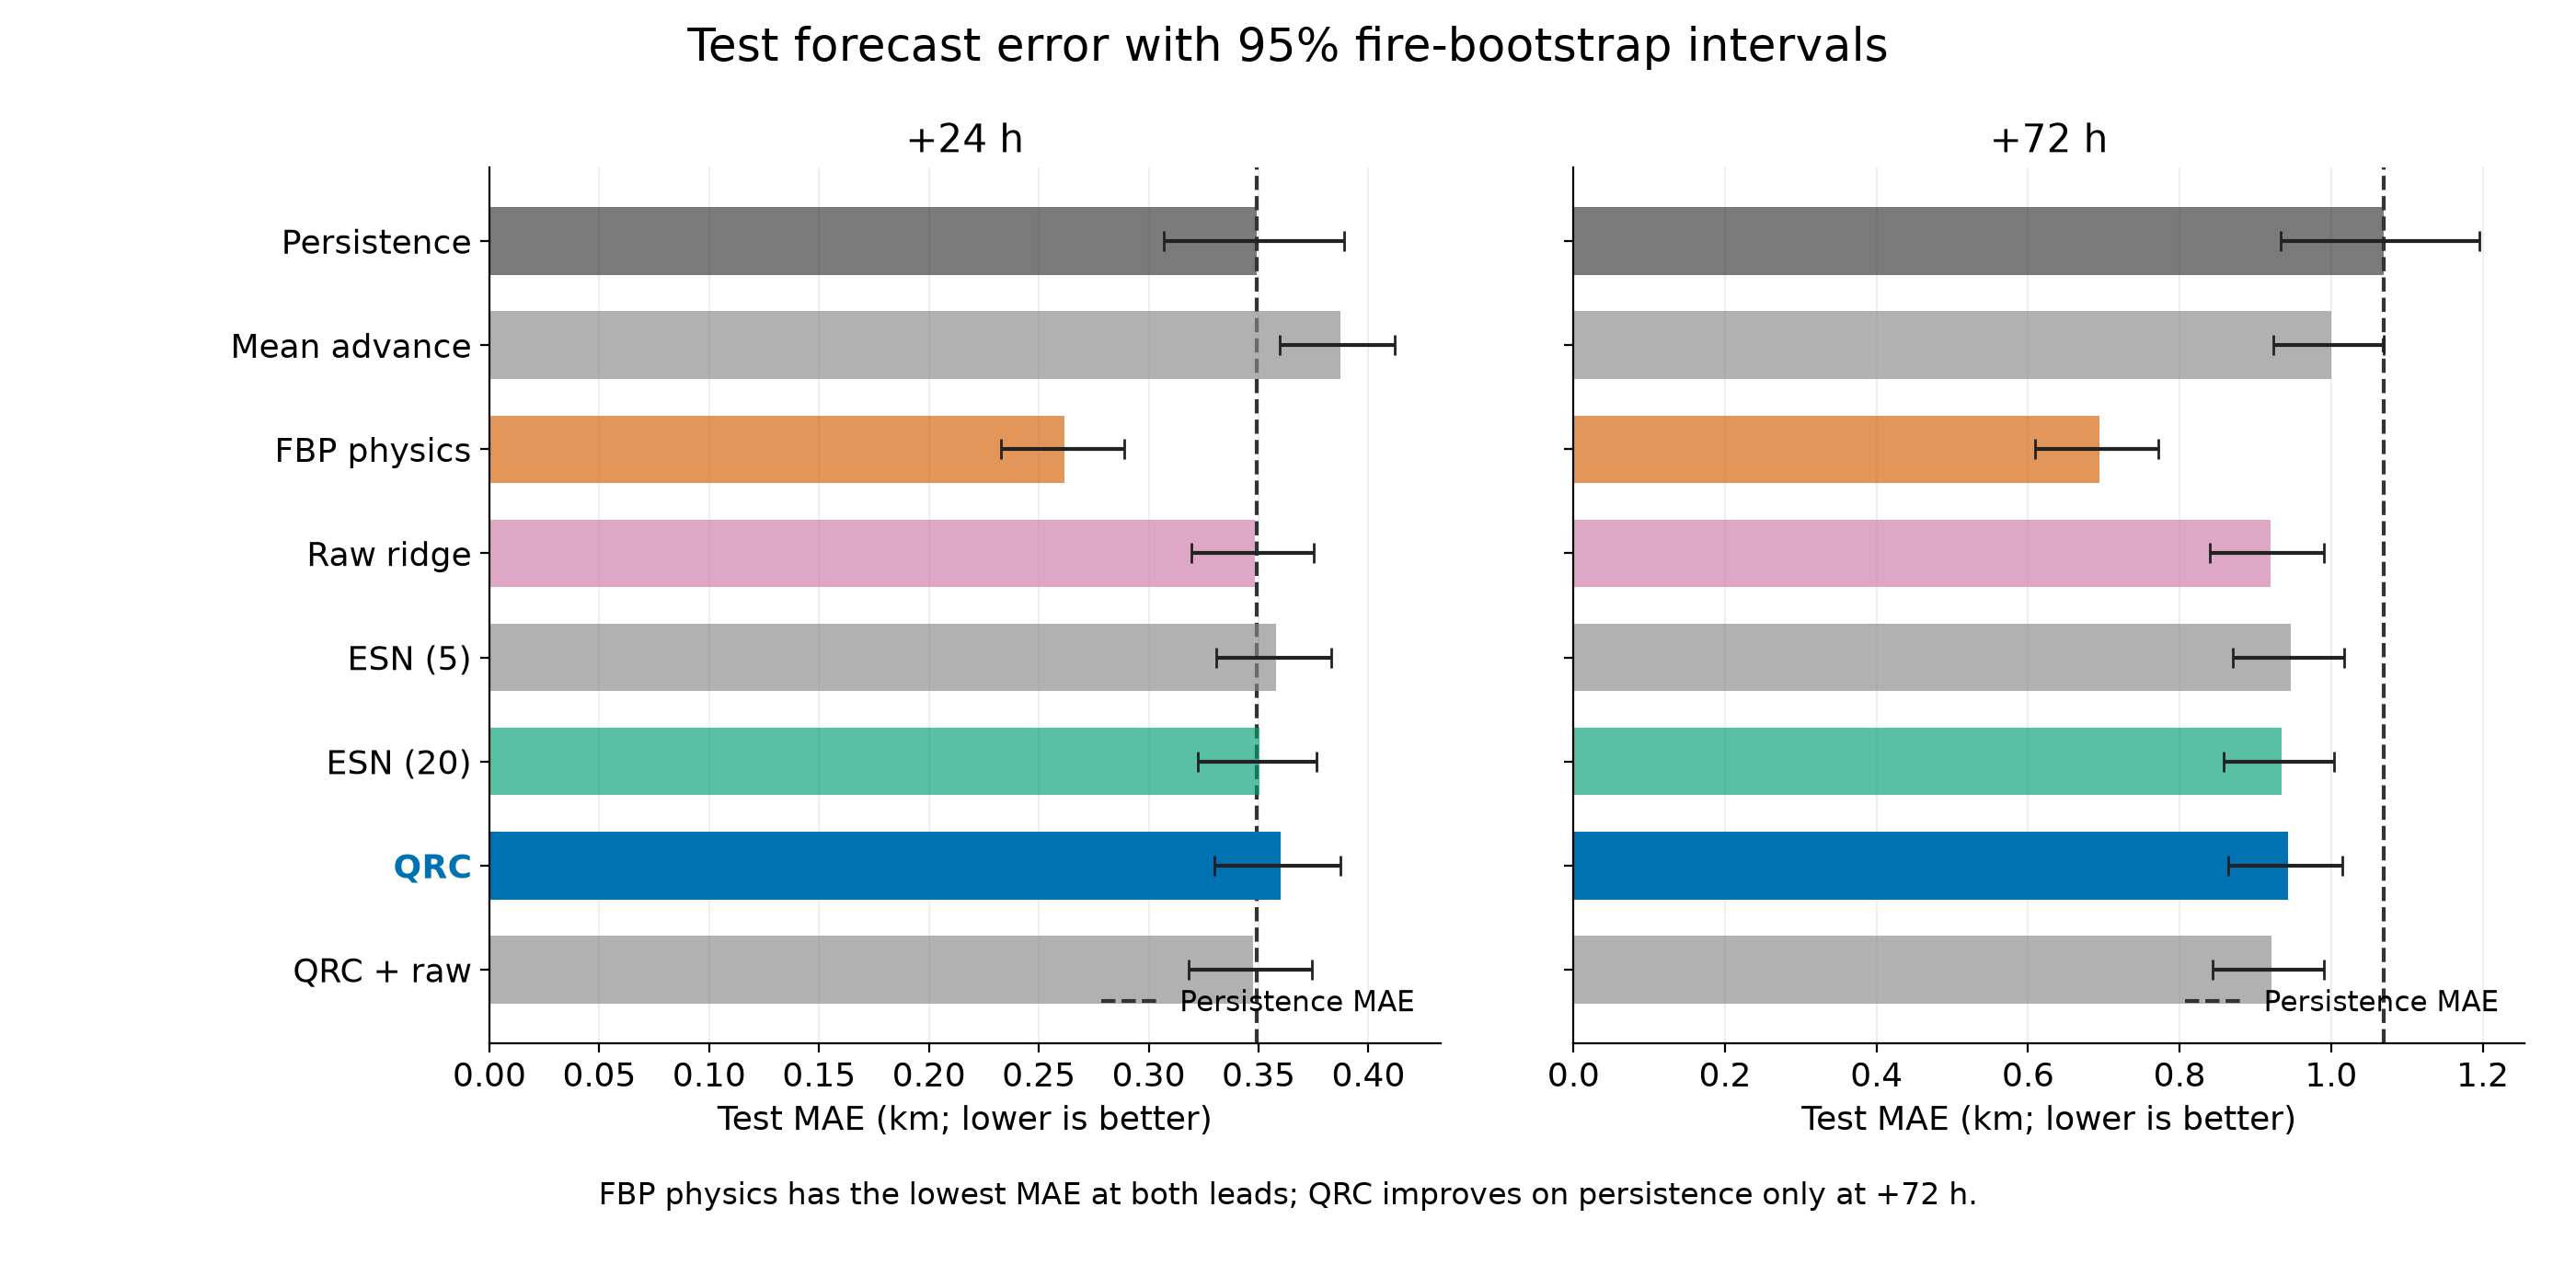

In [9]:
metrics = read_csv("results/metrics.csv")
# haar (random gates instead of CZ) is a design check, left out here.
test = metrics.loc[metrics.split.eq("test") & metrics.model.ne("haar")].copy()
result_table = test[["model", "lead", "skill", "iou", "mae_growing"]].copy()
result_table["lead"] *= 24  # days -> hours
result_table = result_table.rename(columns={"lead": "lead_h"})
result_table.insert(2, "mae [mae_lo, mae_hi]", [
    f"{row.mae:.6f} [{row.mae_lo:.6f}, {row.mae_hi:.6f}]"
    for row in test.itertuples()
])
display(result_table.sort_values(["lead_h", "model"]).reset_index(drop=True))
comparisons = read_csv("results/qrc_comparisons.csv")
comparisons["lead_h"] = comparisons.pop("lead") * 24
print("Paired MAE differences: reservoir minus reference; negative favours the reservoir.")
display(comparisons)
show_figure("e1_test_mae.png")

**Takeaways**
- `qrc` 0.360 / 0.943 km vs `esn20` 0.350 / 0.934: `esn20` clearly better at +24 h, no clear gap at +72 h.
- `raw` ridge beats `qrc` by 0.01–0.02 km (clear).
- `qrc` beats persistence only at +72 h.
- Best MAE: `fbp`. Best IoU: `persistence` (most sectors don't move). Growing sectors: learned models win.

## More qubits and inputs (after freezing)

Exploratory, after the study was frozen. Chart: 2022 validation.

| Version | Adds |
|---|---|
| 7 qubits | upslope + conifer share |
| 10 qubits | + future regional wind, ISI, rain\* |

\*Observed later weather = assumes a perfect forecast (fire's own hotspots removed).
Fair budget: quantum and ESN each try 3 settings × 5 seeds; best 5-seed mean on 2022 kept.
Blue bars = seed 7, trained in this notebook below; lines = range over 5 seeds; ESN bars = 5-seed mean.
Seed 7 is the best of 5 at 10 q; the fair comparison uses seed means (table). 2023 columns are post-hoc.

**Same reservoir code, more qubits:** `ChainReservoir(n=7)` and `ChainReservoir(n=10)`.

| Qubits | Inputs |
|---|---|
| q0–q4 | wind → sector, ISI, today's advance, BUI, humidity (as base) |
| q5–q6 | upslope toward sector, conifer share |
| q7–q9 | future wind → sector, ISI, rain at the lead (10 q only; one model per lead) |

Terrain is read at each day's edge; future values are the same on all 5 days. Next cell builds both
circuits and checks NumPy = Qiskit; the cell after trains and forecasts them.

In [10]:
# 7- and 10-qubit versions: same chain, same frozen gamma and seed, more qubits.
rng = np.random.default_rng(0)
for n in (7, 10):
    big = ChainReservoir(n=n, gamma=frozen["gamma"], seed=frozen["reservoir_seed"])
    window = rng.uniform(size=(frozen["L"], n))  # stand-in inputs in [0, 1]
    qc = big.circuit(window)
    diff = float(np.max(np.abs(big.features_numpy(window) - big.features_exact(window))))
    print(f"{n} qubits: {qc.count_ops()['cz']} CZ, depth {qc.depth()}, "
          f"{len(feature_names(n))} features, max |NumPy - Qiskit| = {diff:.1e}")
    assert diff < 1e-10
print("One day of the 10-qubit circuit:")
print(big.circuit(window[-1:]).draw("text", fold=120))

7 qubits: 30 CZ, depth 29, 35 features, max |NumPy - Qiskit| = 1.1e-15


10 qubits: 45 CZ, depth 32, 65 features, max |NumPy - Qiskit| = 5.6e-16
One day of the 10-qubit circuit:
     ┌─────────────┐   ┌───────────┐┌────────────┐                                                        »
q_0: ┤ Ry(0.37575) ├─■─┤ Ry(1.904) ├┤ Rz(1.7494) ├────────────────────────────────────────────────────────»
     └┬────────────┤ │ └───────────┘├────────────┤┌────────────┐                                          »
q_1: ─┤ Ry(0.6806) ├─■───────■──────┤ Ry(1.6014) ├┤ Rz(2.7965) ├──────────────────────────────────────────»
     ┌┴────────────┤         │      └────────────┘├────────────┤┌────────────┐                            »
q_2: ┤ Ry(0.99701) ├─────────■────────────■───────┤ Ry(3.1702) ├┤ Rz(3.4777) ├────────────────────────────»
     └┬────────────┤                      │       └────────────┘├────────────┤┌────────────┐              »
q_3: ─┤ Ry(0.5405) ├──────────────────────■─────────────■───────┤ Ry(6.2549) ├┤ Rz(4.9804) ├──────────────»
     ┌┴────────────┤           

### Train and forecast: 5, 7, 10 qubits (seed 7, $\gamma=\pi/4$)

Saved inputs (`results/qubit_windows.npz`, from `scripts/export_qubit_windows.py`):
2018–21 train, 2022 val, 88 Yellowknife windows, already scaled.
Steps: reservoir features → ridge on train → $\lambda$ picked on 2022 → forecast. ~1 min.
Check: 2022 MAE must equal the E14 seed-7 row. Blue bars in the chart below = these 2022 numbers. Yellowknife = one fire, descriptive.

In [11]:
GRID = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]

def ridge_fit(X, y, lam):
    # Same as ember/readout.py: centre, then solve (X'X + lam I) w = X'y.
    x_mean, y_mean = X.mean(axis=0), y.mean()
    Xc = X - x_mean
    coef = np.linalg.solve(Xc.T @ Xc + lam * np.eye(X.shape[1]), Xc.T @ (y - y_mean))
    return lambda Z: np.maximum(Z @ coef + (y_mean - x_mean @ coef), 0.0)  # no negative advance

with load_array("results/qubit_windows.npz") as saved:
    daily, static, part = saved["daily"].astype(float), saved["static"].astype(float), saved["part"]
    targets = {1: saved["y1"].astype(float), 3: saved["y3"].astype(float)}
e14_val = read_csv("results/e14_metrics.csv").query(
    "family == 'qrc' and seed == 7 and config == 'gamma=0.25pi' and split == 'val'")

def inputs(version, h):
    if version == "base5":
        return daily[:, :, :5]                       # wind, ISI, advance, BUI, humidity
    if version == "A7":
        return daily                                 # + upslope, conifer share
    future = static[:, :3] if h == 1 else static[:, 3:]  # future wind, ISI, rain at lead h
    return np.concatenate([daily, np.repeat(future[:, None], daily.shape[1], axis=1)], axis=2)

results = []
for version in ("base5", "A7", "B10_h"):
    for h in (1, 3):
        W_v = inputs(version, h)
        X = ChainReservoir(n=W_v.shape[2], gamma=frozen["gamma"],
                           seed=frozen["reservoir_seed"]).feature_matrix(W_v, mode="numpy")
        y = targets[h]
        ok = ~np.isnan(y)
        train, val, yk = ok & (part == 0), ok & (part == 1), ok & (part == 2)
        val_mae = {lam: np.mean(np.abs(y[val] - ridge_fit(X[train], y[train], lam)(X[val])))
                   for lam in GRID}
        lam = min(GRID, key=val_mae.get)             # first lowest, as select_lambda
        forecast = ridge_fit(X[train], y[train], lam)
        saved_val = e14_val.query("version == @version and lead == @h").mae.item()
        assert abs(val_mae[lam] - saved_val) < 1e-6, (version, h)
        results.append({"version": version, "qubits": W_v.shape[2],
                        "features": X.shape[1], "lead_h": 24 * h, "lambda": lam,
                        "val 2022 MAE": round(val_mae[lam], 3), "E14 saved": round(saved_val, 3),
                        "Yellowknife MAE": round(float(np.mean(np.abs(y[yk] - forecast(X[yk])))), 3),
                        "Yellowknife n": int(yk.sum())})
display(pd.DataFrame(results))

,version,qubits,features,lead_h,lambda,val 2022 MAE,E14 saved,Yellowknife MAE,Yellowknife n
0,base5,5,20,24,0.000001,0.303000,0.303000,0.278000,88
1,base5,5,20,72,0.000001,0.767000,0.767000,1.002000,88
2,A7,7,35,24,0.000001,0.300000,0.300000,0.345000,88
3,A7,7,35,72,0.000001,0.761000,0.761000,1.138000,88
4,B10_h,10,65,24,0.000010,0.276000,0.276000,0.268000,88
5,B10_h,10,65,72,0.000100,0.666000,0.666000,0.904000,88


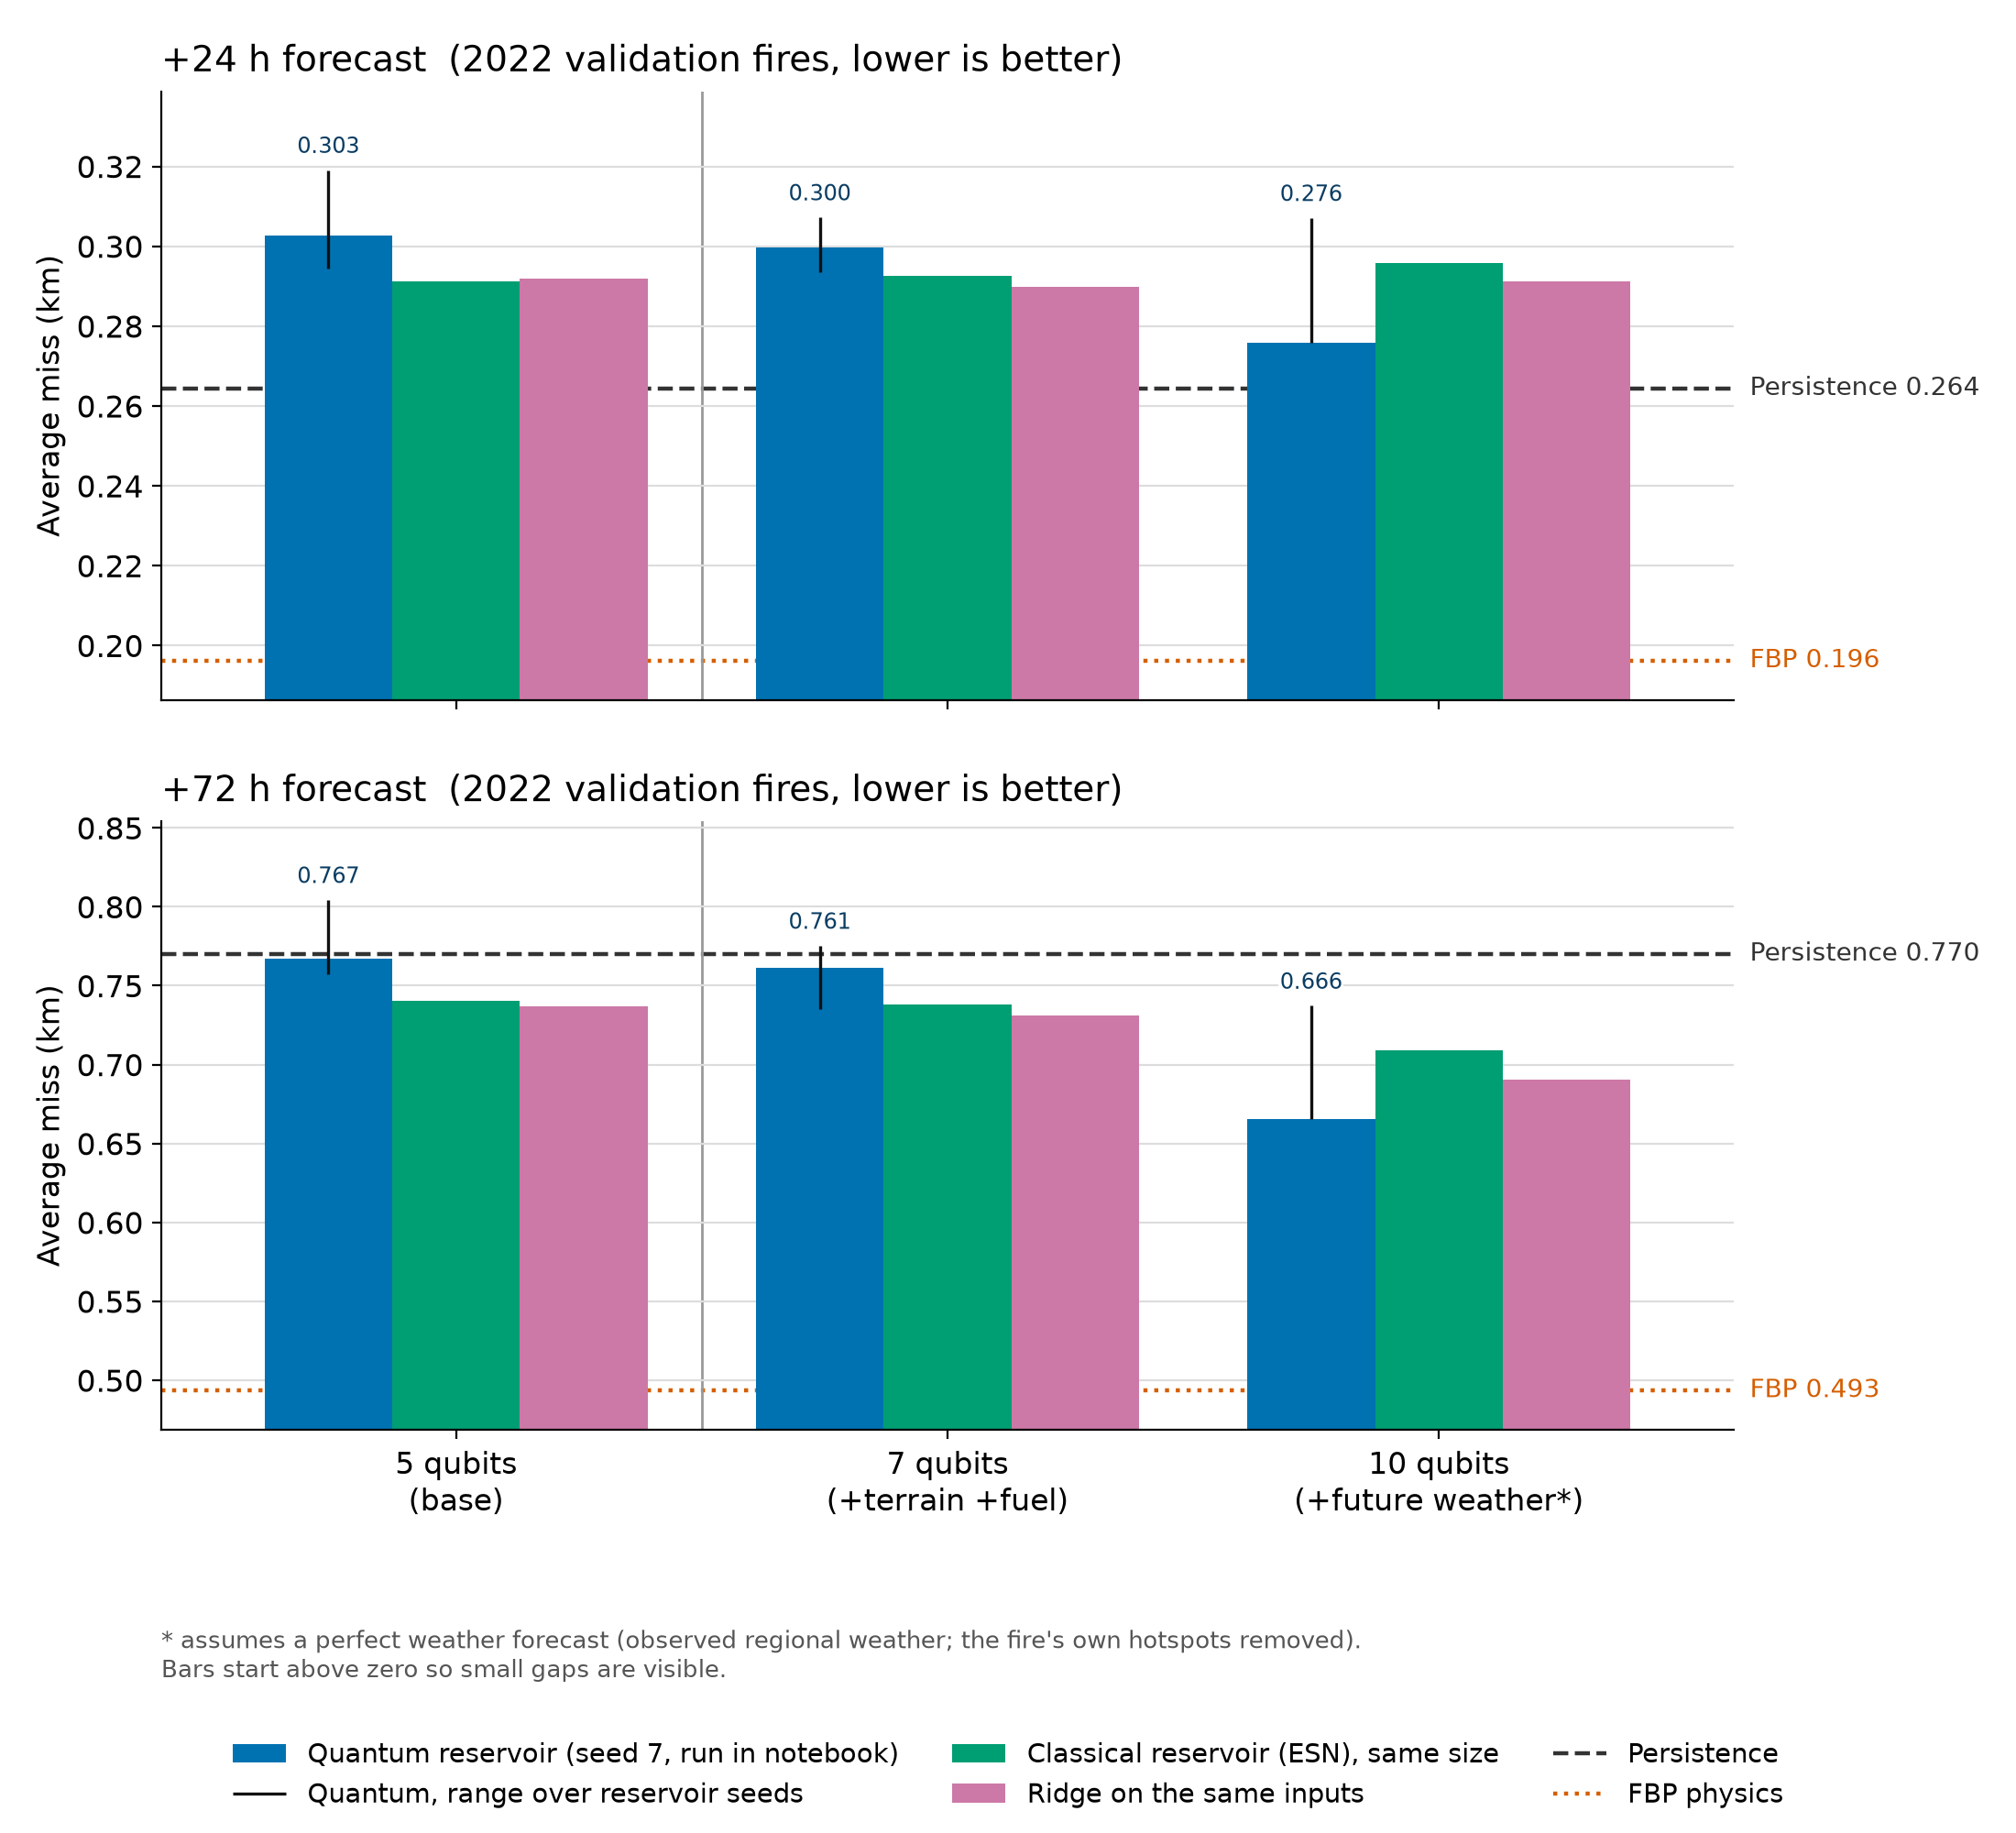

Chart blue bars match the seed-7 run above.
MAE (km): mean [min-max] over 5 seeds, for the setting chosen on 2022


,version,model,lead_h,setting,val 2022,2023 (post-hoc)
0,5 qubits (base),quantum,24,gamma=0.25pi,0.306 [0.295-0.319],0.362 [0.354-0.373]
1,5 qubits (base),ESN,24,input_scale=0.3,0.291 [0.289-0.293],0.347 [0.346-0.350]
2,5 qubits (base),ridge,24,raw,0.292,0.348
3,7 qubits (+terrain +fuel),quantum,24,gamma=0.25pi,0.301 [0.294-0.307],0.357 [0.351-0.362]
4,7 qubits (+terrain +fuel),ESN,24,input_scale=0.3,0.293 [0.291-0.294],0.348 [0.343-0.355]
5,7 qubits (+terrain +fuel),ridge,24,raw,0.290,0.342
6,10 qubits (+future weather),quantum,24,gamma=0.25pi,0.290 [0.276-0.307],0.348 [0.338-0.358]
7,10 qubits (+future weather),ESN,24,input_scale=0.3,0.296 [0.294-0.299],0.351 [0.347-0.353]
8,10 qubits (+future weather),ridge,24,raw,0.291,0.342
9,5 qubits (base),quantum,72,gamma=0.25pi,0.774 [0.757-0.804],0.950 [0.939-0.978]


Paired 2023 differences in seed-averaged error (km), 95% fire bootstrap; negative favours the first model.


,version,lead_h,comparison,diff,lo,hi
0,5 qubits (base),24,quantum minus ridge,0.014261,0.012818,0.015597
1,5 qubits (base),24,quantum minus ESN,0.015161,0.013899,0.016406
2,5 qubits (base),24,ESN minus ridge,-0.000900,-0.001373,-0.000450
3,5 qubits (base),72,quantum minus ridge,0.030187,0.025896,0.034231
4,5 qubits (base),72,quantum minus ESN,0.027373,0.023075,0.031253
5,5 qubits (base),72,ESN minus ridge,0.002814,0.001909,0.003790
6,7 qubits (+terrain +fuel),24,quantum minus ridge,0.014375,0.012541,0.016272
7,7 qubits (+terrain +fuel),24,quantum minus ESN,0.009036,0.007116,0.010989
8,7 qubits (+terrain +fuel),24,ESN minus ridge,0.005339,0.004005,0.006694
9,7 qubits (+terrain +fuel),72,quantum minus ridge,0.034589,0.030375,0.039066


In [12]:
show_figure("qubit_comparison.png")
bars = read_csv("results/qubit_comparison_val.csv")
for row in results:  # chart blue bars = this notebook's seed-7 run
    h = row["lead_h"] // 24
    bar = bars.query("qubits == @row['qubits'] and lead == @h").quantum.item()
    assert abs(bar - row["val 2022 MAE"]) < 5e-4, row
print("Chart blue bars match the seed-7 run above.")
version_labels = {"base5": "5 qubits (base)", "A7": "7 qubits (+terrain +fuel)",
          "B10_h": "10 qubits (+future weather)"}
family_names = {"qrc": "quantum", "esn": "ESN", "raw": "ridge"}
e14_selected = read_csv("results/e14_selected.csv")

def span(row, split):
    mean, lo, hi = row[f"{split}_mean"], row[f"{split}_min"], row[f"{split}_max"]
    return f"{mean:.3f}" if row.n_seeds == 1 else f"{mean:.3f} [{lo:.3f}-{hi:.3f}]"

e14_table = pd.DataFrame({"version": e14_selected.version.map(version_labels), "model": e14_selected.family.map(family_names),
                      "lead_h": e14_selected.lead * 24, "setting": e14_selected.config,
                      "val 2022": e14_selected.apply(span, axis=1, split="val"),
                      "2023 (post-hoc)": e14_selected.apply(span, axis=1, split="test")})
print("MAE (km): mean [min-max] over 5 seeds, for the setting chosen on 2022")
display(e14_table.sort_values("lead_h", kind="stable").reset_index(drop=True))
e14_paired = read_csv("results/e14_paired.csv")
e14_paired = e14_paired.loc[e14_paired.split.eq("test")].assign(
    version=lambda d: d.version.map(version_labels), lead_h=lambda d: d.lead * 24,
    comparison=lambda d: d.model.map(family_names) + " minus " + d.reference.map(family_names))
print("Paired 2023 differences in seed-averaged error (km), 95% fire bootstrap; "
      "negative favours the first model.")
display(e14_paired[["version", "lead_h", "comparison", "diff", "lo", "hi"]].reset_index(drop=True))

**Takeaway (seed means, fair):** ridge on raw inputs is best or within 0.0015 km of best everywhere. 5 q and 7 q: quantum loses
to ridge and tuned ESN (both leads, both years). 10 q: ties ridge on 2022; on 2023 loses
to ridge (+0.006 / +0.027 km) and beats ESN by a little (−0.003 / −0.008 km), the only
quantum edge left. Seed spread is wide (10 q, 2022, +24 h: 0.276–0.307 km). Both picked
the smallest setting tried (γ = π/4, input scale 0.3); a wider grid might move them.
Perfect forecasts don't exist → 10 q is a best case.

## Real hardware (E6)

Yellowknife fire, `ibm_fez`: 88 circuits × 10,000 shots, Z basis → 15 Z/ZZ features (saved).
Why 10,000 shots: in simulation, +24 h MAE 0.41 km vs 0.36 exact (100 shots: 1.21 km).

**No IBM connection here.** The next cells replay it:
1. Job record.
2. Measured features × saved ridge weights (trained on simulation only) → forecast →
   MAE; must match the saved score within $10^{-9}$ km.

In [13]:
# The job record saved when the circuits ran on ibm_fez.
job_metrics = read_json("hardware/e6_job_metrics.json")
meta = read_json("results/e6_meta.json")
jobs = read_json("hardware/jobs.json")
job = next(row for row in jobs if row["job_id"] == job_metrics["job_id"])
assert meta["job_id"] == job["job_id"]
assert meta["backend"] == job["backend"]
assert meta["shots"] == job["budget"]["shots"]
display(pd.DataFrame([{
    "job_id": job_metrics["job_id"],
    "backend": meta["backend"],
    "shots_per_circuit": meta["shots"],
    "circuits": len(W),
    "qpu_seconds": job_metrics["usage"]["qpu_charge_time_seconds"],
}]))

,job_id,backend,shots_per_circuit,circuits,qpu_seconds
0,dbm0tm58ft8s738tu920,ibm_fez,10000,88,238


E6 +24 h absolute MAE difference: 0.000000000000e+00 km
E6 +72 h absolute MAE difference: 0.000000000000e+00 km


,lead_h,recomputed_mae,saved_mae,absolute_difference
0,24,0.257881,0.257881,0.000000
1,72,0.979314,0.979314,0.000000


,source,lead,mae,n_rows,feature_mae
0,exact,1,0.272408,88,0.000000
1,fake_fez,1,0.277193,88,0.043793
2,hardware,1,0.257881,88,0.072526
3,persistence,1,0.300678,88,NaN
4,exact,3,1.001495,88,0.000000
5,fake_fez,3,1.005559,88,0.043793
6,hardware,3,0.979314,88,0.072526
7,persistence,3,1.228193,88,NaN


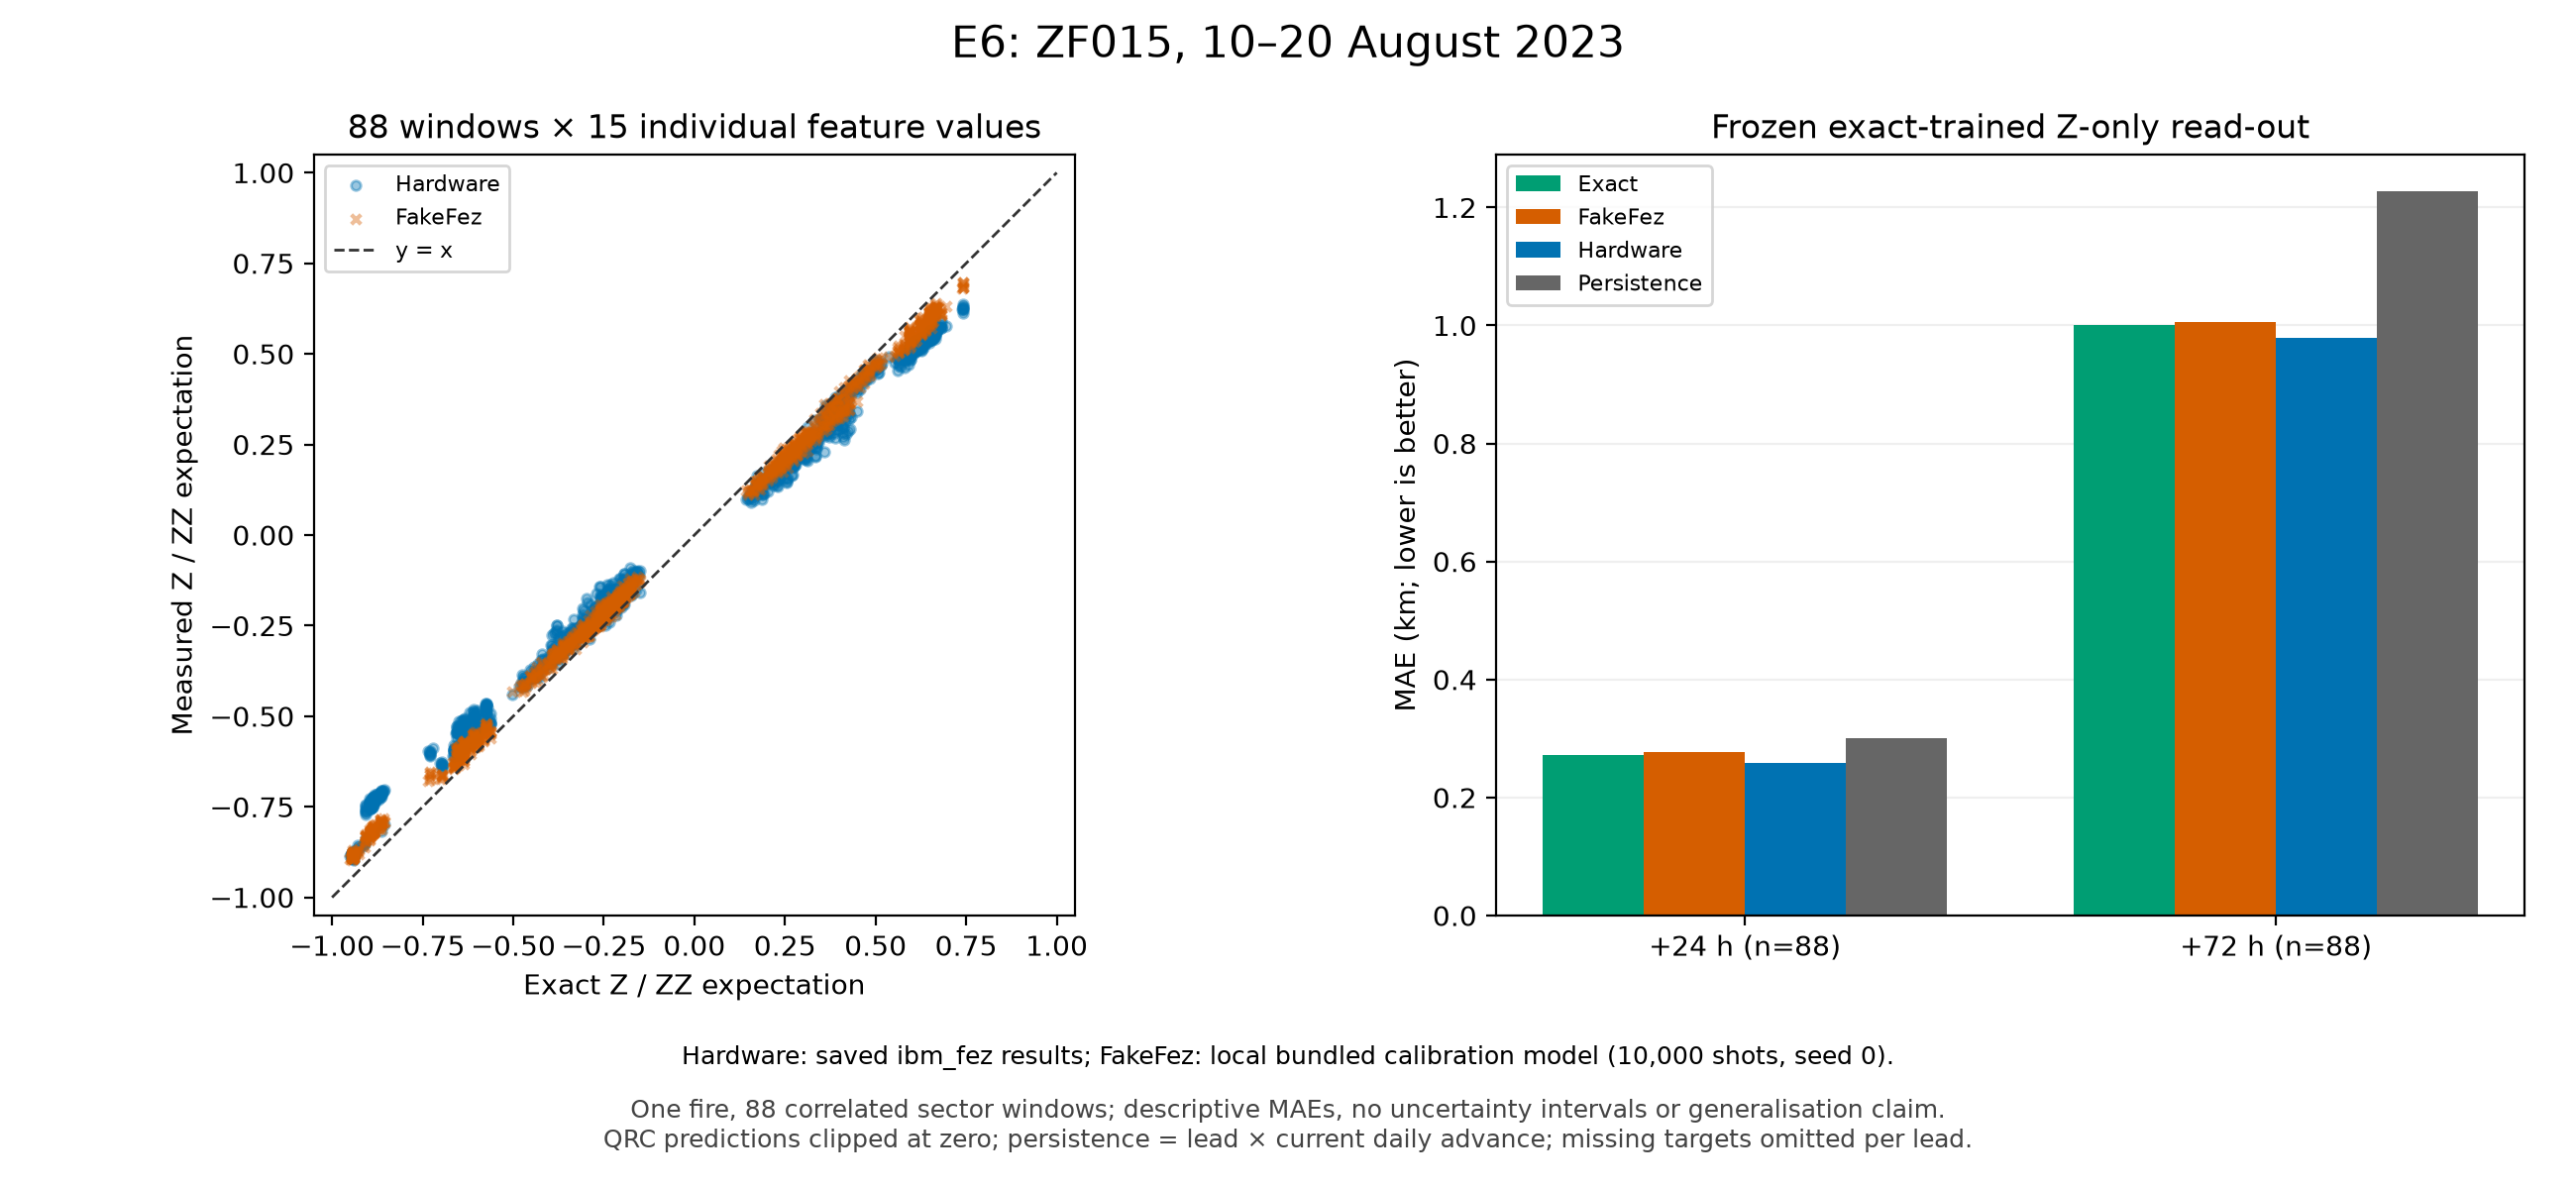

In [14]:
# E6 live recomputation from measured features and frozen weights.
readout = read_json("results/qrc_z_readout.json")
measured = load_array("hardware/e6_hw_features.npy")
assert measured.shape == (len(W), len(readout["feature_names"]))
assert readout["feature_names"] == names[:measured.shape[1]]
assert np.isfinite(measured).all()
assert np.all((W >= 0) & (W <= 1))
assert len(readout["scaler"]["lo"]) == W.shape[-1]
saved_predictions = read_csv("results/e6_predictions.csv", parse_dates=["date"])
hardware_scores = read_csv("results/e6_hardware.csv")
checks = []
for lead in (1, 3):
    # Forecast = measured features x saved weights + intercept, clipped at 0.
    fit = readout["readouts"][str(lead)]
    predicted = np.maximum(
        measured @ np.asarray(fit["coefficients"]) + fit["intercept"],
        readout["prediction_clip_min"],
    )
    # Match each forecast to its true advance by date and sector.
    targets = saved_predictions.loc[saved_predictions.lead.eq(lead), ["date", "sector", "y"]]
    joined = case_rows.assign(yhat=predicted).merge(
        targets, on=["date", "sector"], how="left", sort=False, validate="one_to_one"
    )
    keep = joined.y.notna()
    reference = hardware_scores.loc[
        hardware_scores.source.eq("hardware") & hardware_scores.lead.eq(lead)
    ].iloc[0]
    assert int(keep.sum()) == int(reference.n_rows)
    recomputed = mae(joined.loc[keep, "y"], joined.loc[keep, "yhat"])
    difference = abs(recomputed - reference.mae)
    print(f"E6 +{lead * 24} h absolute MAE difference: {difference:.12e} km")
    assert difference < 1e-9
    checks.append({"lead_h": lead * 24, "recomputed_mae": recomputed,
                   "saved_mae": reference.mae, "absolute_difference": difference})
display(pd.DataFrame(checks))
display(hardware_scores)
show_figure("e6_hardware.png")

**Takeaway:** hardware 0.258 / 0.979 km vs exact 0.272 / 1.001 km; both beat
persistence. Average error survives noise; single forecasts differ from exact by 0.07 / 0.24 km on
average (max 0.57 / 1.37). One fire, so not evidence hardware is better.
(`feature_mae` = average gap from exact features.)

## ZF015 / Yellowknife case

~20,000 people evacuated, August 2023. Map: rebuilt outlines, forecasts, CWFIS season-end outline.

Town lies in sector 3 (SE), but the closest fire approach is the south lobe, sector 4,
~25 km. Arrival-time estimates (constant speed) give 38–1,355 days → not reported.

Yellowknife: 66.7 km from the fire centre, sector 3.


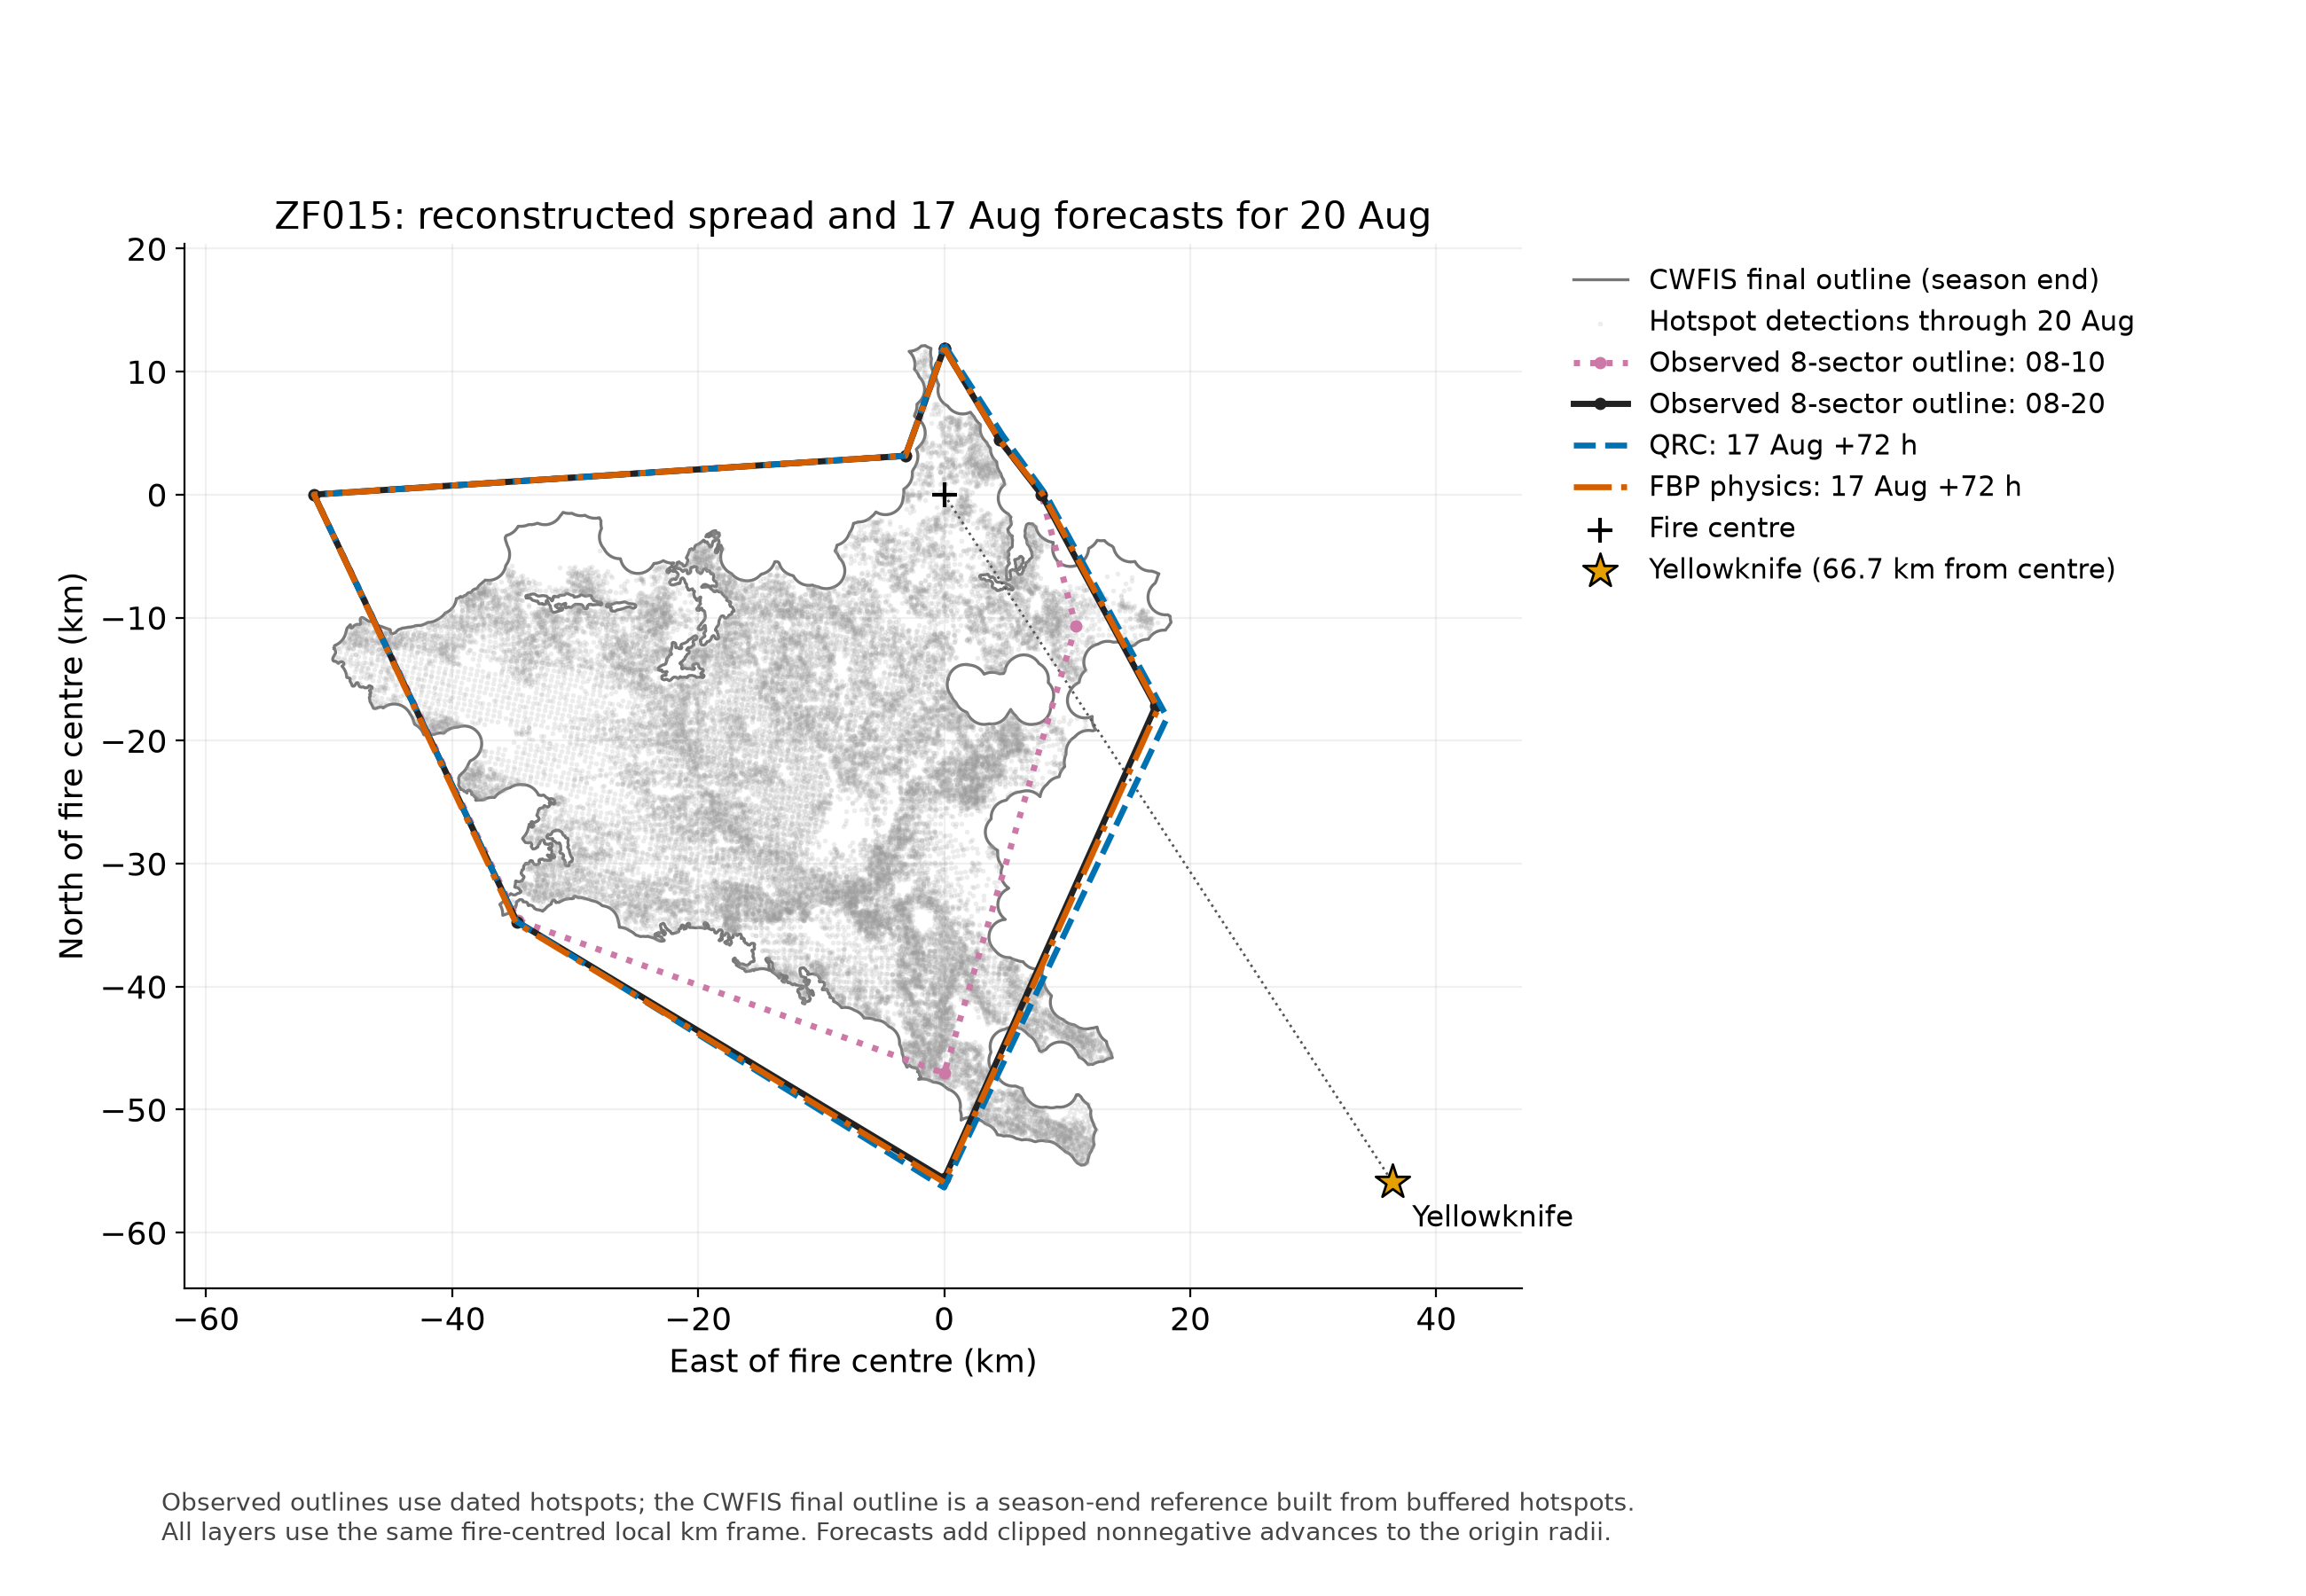

In [15]:
location = read_json("results/e8_eta.json")
print(f"{location['town']}: {location['distance_km']:.1f} km from the fire centre, sector {location['sector']}.")
show_figure("e8_zf015_map.png")

## Conclusions and limits

- Quantum close to classical reservoirs (worse than `esn20` at +24 h); slightly behind raw ridge. No quantum advantage.
- FBP: lowest MAE. Persistence: best IoU. Growing sectors: learned models win.
- Beats persistence only at +72 h.
- Real hardware: MAE within 0.014 / 0.022 km of exact; single forecasts differ by 0.07 / 0.24 km on average (one fire).
- More qubits (post-hoc): 10 q ties ridge on 2022 and slightly beats tuned ESN; needs a perfect weather forecast.
- Limits: one hardware case · no forecast for a fire's first 2 days · 30 km/day cap can merge fires ·
  no fuel-type input (base model) · 375 m–1 km satellite pixels.

### Reproduce

With the source data (README: 'Rebuild everything from the raw data'), run from the
repository root with `.venv/bin/python -I`:

1. `scripts/build_sectors.py`
2. `scripts/run_experiments.py`
3. `scripts/run_u5b.py`
4. `scripts/make_figures.py`
5. `scripts/e6_hardware.py`
6. `scripts/e10_rebuild_check.py --year 2023` (E10 shape check)
7. `scripts/e13_build_drivers.py` (terrain, fuel, weather inputs for the more-qubit versions)
8. `scripts/e14_fair_baselines.py`, then `scripts/plot_qubit_comparison.py`
9. `scripts/export_qubit_windows.py` (7/10-qubit inputs trained here)
10. `scripts/build_notebook_explained.py` (this notebook)